# 05 Least squares and ridge regression: model selection with cross-validation

This notebook trains the two closed-form models from `implementations.py`, **`least_squares`** and
**`ridge_regression`**, and selects their hyperparameters with **stratified 5-fold cross-validation**.
(The gradient-based models are covered in the team's other notebooks: MSE GD in 03, regularized logistic
regression in 04.) It uses the modules at the repo root:

| Module | What it gives us |
|---|---|
| `metrics.py` | accuracy, precision, recall, F1, `best_f1_threshold` |
| `cross_validation.py` | `build_k_indices`, `cross_validation`, in-fold under/oversampling |
| `grid_search.py` | `grid_search` over a hyperparameter grid, same folds for every combination |

**Data:** `dataset/prepared/clean_full.npz`. This is the cleaned training set with the *original* class
distribution (about 9% positives) and standardized features. We do **not** use the pre-oversampled
datasets here; section 6 shows why.

**Metric:** F1 on the positive class (AIcrowd metric). Both models output a score `tx @ w`, and the decision
threshold is tuned for F1 on the out-of-fold scores.

Full run time: about 2 minutes on a laptop.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().resolve().parent
if not (PROJECT_ROOT / "implementations.py").exists():
    PROJECT_ROOT = Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from cross_validation import (
    build_k_indices,
    cross_validation,
    random_oversample,
    random_undersample,
)
from grid_search import format_params, grid_search, load_prepared, print_results
from metrics import best_f1_threshold, compute_metrics, predict_labels

# NumPy 2.0 with Apple's Accelerate BLAS emits spurious "divide by zero / overflow /
# invalid value encountered in matmul" warnings on perfectly finite data.
# The results are correct, so we silence them.
warnings.filterwarnings("ignore", message=".*encountered in matmul")

K_FOLD = 5
SEED = 1

# Plot style: categorical colors in fixed order, thin lines, recessive grid.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "lines.linewidth": 2,
    "font.size": 10,
})

In [2]:
y, tx = load_prepared(PROJECT_ROOT / "dataset/prepared/clean_full.npz")
N, D = tx.shape

print(f"tx: {tx.shape} (bias column + {D - 1} features)")
print(f"positives: {y.sum()} / {N} = {y.mean():.2%}")
print(f"feature means in [{tx[:, 1:].mean(0).min():.1e}, {tx[:, 1:].mean(0).max():.1e}], "
      f"stds in [{tx[:, 1:].std(0).min():.3f}, {tx[:, 1:].std(0).max():.3f}]  -> already standardized")

tx: (328135, 155) (bias column + 154 features)
positives: 28975 / 328135 = 8.83%
feature means in [-7.4e-09, 1.0e+00], stds in [0.003, 1.000]  -> already standardized


## 1. Why accuracy is not enough

With about 9% positives, a model that **always predicts "no heart disease"** already gets about 91% accuracy.
F1 is 0 for that model, which is why we select models on F1.

In [3]:
baselines = {
    "always 0": np.zeros_like(y),
    "always 1": np.ones_like(y),
    "random (p = 0.5)": (np.random.default_rng(SEED).random(N) < 0.5).astype(int),
}
print(f"{'predictor':<18} {'accuracy':>8} {'precision':>9} {'recall':>6} {'F1':>6}")
for name, y_pred in baselines.items():
    m = compute_metrics(y, y_pred)
    print(f"{name:<18} {m['accuracy']:>8.4f} {m['precision']:>9.4f} {m['recall']:>6.4f} {m['f1']:>6.4f}")

predictor          accuracy precision recall     F1
always 0             0.9117    0.0000 0.0000 0.0000
always 1             0.0883    0.0883 1.0000 0.1623
random (p = 0.5)     0.4992    0.0885 0.5024 0.1505


## 2. Stratified folds

`build_k_indices` splits **every** row into exactly one fold (no rows dropped), and with
`stratified=True` each fold keeps the same positive rate. Below we compare it with a plain random split.

In [4]:
k_indices = build_k_indices(y, K_FOLD, seed=SEED, stratified=True)
k_indices_plain = build_k_indices(y, K_FOLD, seed=SEED, stratified=False)

print(f"{'fold':>4} {'size':>7} {'pos. rate (stratified)':>23} {'pos. rate (plain)':>18}")
for k in range(K_FOLD):
    print(f"{k:>4} {len(k_indices[k]):>7} {y[k_indices[k]].mean():>23.4%} {y[k_indices_plain[k]].mean():>18.4%}")

all_idx = np.concatenate(k_indices)
assert len(all_idx) == N == len(np.unique(all_idx)), "folds must partition the data"
print("\nEvery row is in exactly one fold.")

fold    size  pos. rate (stratified)  pos. rate (plain)
   0   65627                 8.8302%            8.9155%
   1   65627                 8.8302%            8.7723%
   2   65627                 8.8302%            8.7327%
   3   65627                 8.8302%            8.7997%
   4   65627                 8.8302%            8.9308%

Every row is in exactly one fold.


## 3. Least squares baseline, and why the threshold matters

Least squares regresses on y ∈ {0, 1}, so its score `tx @ w` is roughly a probability. The usual
threshold of 0.5 almost never predicts a positive. Tuning the threshold for F1 makes a big difference.

In [5]:
ls_tuned = cross_validation(y, tx, "least_squares", {}, k_indices)
ls_fixed = cross_validation(y, tx, "least_squares", {}, k_indices, threshold=0.5)

for name, r in [("threshold = 0.5", ls_fixed), (f"tuned ({ls_tuned['threshold']:.3f})", ls_tuned)]:
    print(f"{name:<18} F1 = {r['f1_mean']:.4f} ± {r['f1_std']:.4f}   "
          f"precision = {r['precision_mean']:.4f}   recall = {r['recall_mean']:.4f}   "
          f"accuracy = {r['accuracy_mean']:.4f}")

threshold = 0.5    F1 = 0.0894 ± 0.0040   precision = 0.6642   recall = 0.0479   accuracy = 0.9138
tuned (0.210)      F1 = 0.4105 ± 0.0062   precision = 0.3349   recall = 0.5301   accuracy = 0.8655


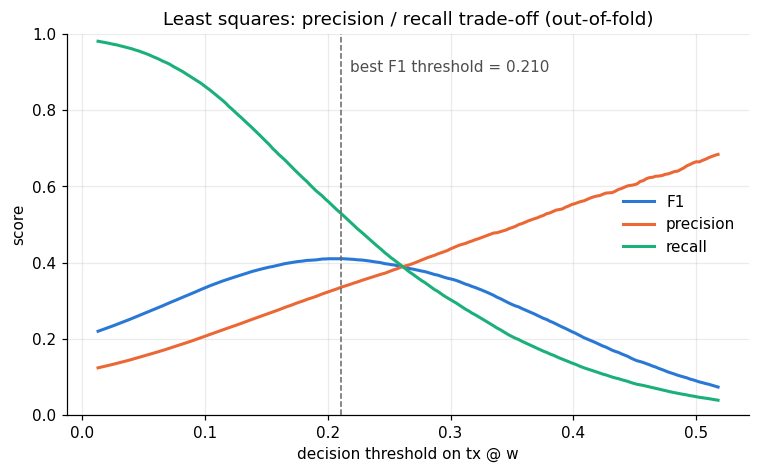

In [6]:
# F1 / precision / recall as a function of the threshold, on the out-of-fold scores.
scores = ls_tuned["oof_scores"]
thresholds = np.linspace(np.quantile(scores, 0.30), np.quantile(scores, 0.995), 200)
curves = np.array([
    [compute_metrics(y, predict_labels(scores, t))[name] for name in ("f1", "precision", "recall")]
    for t in thresholds
])

fig, ax = plt.subplots()
for (label, color), values in zip([("F1", BLUE), ("precision", ORANGE), ("recall", AQUA)], curves.T):
    ax.plot(thresholds, values, color=color, label=label)
best_thr = ls_tuned["threshold"]
ax.axvline(best_thr, color="0.4", linestyle="--", linewidth=1)
ax.annotate(f"best F1 threshold = {best_thr:.3f}", (best_thr, 0.9),
            xytext=(6, 0), textcoords="offset points", color="0.3")
ax.set_xlabel("decision threshold on tx @ w")
ax.set_ylabel("score")
ax.set_ylim(0, 1)
ax.set_title("Least squares: precision / recall trade-off (out-of-fold)")
ax.legend(frameon=False, loc="center right")
plt.show()

## 4. Ridge regression: grid search over λ

`ridge_regression` minimizes MSE + λ‖w‖², with a closed-form solution, so each fit takes well under a
second. We search λ on a log scale. The shaded band is ± 1 std over the 5 folds.

In [7]:
lambdas = np.logspace(-8, 0, 17)
start = time.time()
best_ridge, ridge_results = grid_search(y, tx, "ridge_regression", {"lambda_": lambdas},
                                        k_fold=K_FOLD, seed=SEED, verbose=False)
print(f"{len(lambdas)} values of lambda x {K_FOLD} folds in {time.time() - start:.1f}s")
print_results(ridge_results, top=5)

17 values of lambda x 5 folds in 16.7s

rank               F1  accuracy  precision  recall  threshold  params
   1  0.4122 ± 0.0067    0.8648     0.3346  0.5368     0.2073  lambda_=0.001
   2  0.4119 ± 0.0066    0.8650     0.3347  0.5356     0.2087  lambda_=0.000316
   3  0.4114 ± 0.0060    0.8587     0.3254  0.5591     0.1985  lambda_=0.00316
   4  0.4109 ± 0.0066    0.8666     0.3368  0.5268     0.2116  lambda_=0.0001
   5  0.4107 ± 0.0062    0.8656     0.3351  0.5303     0.2104  lambda_=3.16e-05


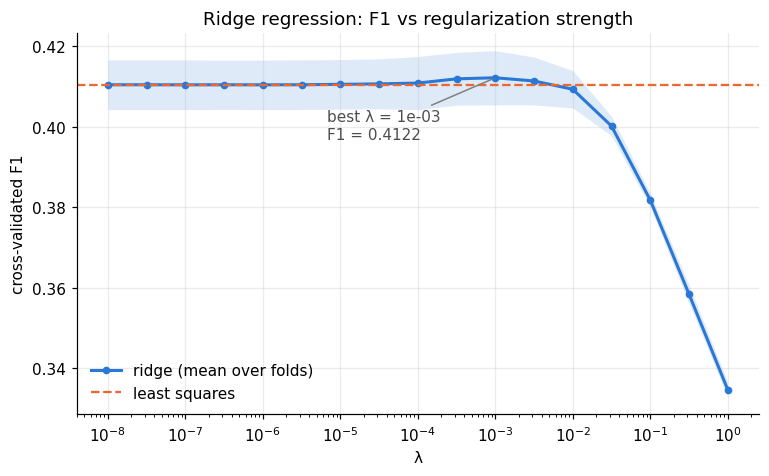

In [8]:
f1_mean = np.array([r["f1_mean"] for r in ridge_results])
f1_std = np.array([r["f1_std"] for r in ridge_results])

fig, ax = plt.subplots()
ax.fill_between(lambdas, f1_mean - f1_std, f1_mean + f1_std, color=BLUE, alpha=0.15, linewidth=0)
ax.plot(lambdas, f1_mean, color=BLUE, marker="o", markersize=4, label="ridge (mean over folds)")
ax.axhline(ls_tuned["f1_mean"], color=ORANGE, linestyle="--", linewidth=1.5, label="least squares")
best_lambda = best_ridge["params"]["lambda_"]
ax.annotate(f"best λ = {best_lambda:.0e}\nF1 = {best_ridge['f1_mean']:.4f}",
            (best_lambda, best_ridge["f1_mean"]), xytext=(-110, -40), textcoords="offset points",
            arrowprops={"arrowstyle": "-", "color": "0.5"}, color="0.3")
ax.set_xscale("log")
ax.set_xlabel("λ")
ax.set_ylabel("cross-validated F1")
ax.set_title("Ridge regression: F1 vs regularization strength")
ax.legend(frameon=False, loc="lower left")
plt.show()

## 5. Class imbalance: does rebalancing the training folds help ridge?

With the best λ, we compare three ways of training on the same folds:

- **none**: train on the folds as they are (about 9% positives)
- **undersample**: keep all positives and the same number of random negatives (training folds only)
- **oversample**: duplicate random positives until the classes are balanced (training folds only)

The validation fold always keeps the real class distribution, and the threshold is tuned in every case.

In [9]:
ridge_params = best_ridge["params"]
ridge_balance = {}
for name, resample_fn in [("none", None), ("undersample", random_undersample),
                          ("oversample", random_oversample)]:
    r = cross_validation(y, tx, "ridge_regression", ridge_params, k_indices, resample_fn=resample_fn)
    ridge_balance[name] = r
    print(f"{name:<12} F1 = {r['f1_mean']:.4f} ± {r['f1_std']:.4f}   precision = {r['precision_mean']:.4f}   "
          f"recall = {r['recall_mean']:.4f}   threshold = {r['threshold']:.4f}")

none         F1 = 0.4122 ± 0.0067   precision = 0.3346   recall = 0.5368   threshold = 0.2073
undersample  F1 = 0.4202 ± 0.0042   precision = 0.3424   recall = 0.5437   threshold = 0.6725
oversample   F1 = 0.4196 ± 0.0045   precision = 0.3430   recall = 0.5402   threshold = 0.6725


## 6. Data leakage: never oversample before splitting

`selected_random_over_dataset.npz` contains `x_train`, which was **already oversampled** (positives duplicated
up to 1/3 of the rows), and `x_train_raw`, the original rows. If we cross-validate on the oversampled
matrix, copies of the same positive end up in both the training and validation folds. The model is then
scored partly on rows it has memorized, and the validation fold no longer has the real class ratio.

We compare that with the correct procedure: split first, then oversample **only the training folds**
to the same ratio (positives = ½ × negatives).

In [10]:
over = np.load(PROJECT_ROOT / "dataset/prepared/selected_random_over_dataset.npz", allow_pickle=True)
tx_over = np.c_[np.ones(len(over["x_train"])), over["x_train"].astype(np.float64)]
y_over = (over["y_train"] == 1).astype(int)
tx_raw = np.c_[np.ones(len(over["x_train_raw"])), over["x_train_raw"].astype(np.float64)]
y_raw = (over["y_train_raw"] == 1).astype(int)

params = {"lambda_": best_ridge["params"]["lambda_"]}

leaky = cross_validation(y_over, tx_over, "ridge_regression", params,
                         build_k_indices(y_over, K_FOLD, seed=SEED))
correct = cross_validation(y_raw, tx_raw, "ridge_regression", params,
                           build_k_indices(y_raw, K_FOLD, seed=SEED),
                           resample_fn=lambda x, y, seed: random_oversample(x, y, seed, ratio=0.5))

print(f"positives in validation folds: leaky = {y_over.mean():.1%}, correct = {y_raw.mean():.1%}\n")
print(f"oversample THEN split (leaky):   F1 = {leaky['f1_mean']:.4f} ± {leaky['f1_std']:.4f}")
print(f"split THEN oversample (correct): F1 = {correct['f1_mean']:.4f} ± {correct['f1_std']:.4f}")

positives in validation folds: leaky = 33.3%, correct = 8.8%

oversample THEN split (leaky):   F1 = 0.7010 ± 0.0008
split THEN oversample (correct): F1 = 0.4197 ± 0.0050


## 7. Summary

In [11]:
summary = [
    ("least squares, threshold 0.5", ls_fixed, {}),
    ("least squares, tuned threshold", ls_tuned, {}),
    ("ridge regression", best_ridge, best_ridge["params"]),
    ("ridge + undersample", ridge_balance["undersample"], best_ridge["params"]),
    ("ridge + oversample", ridge_balance["oversample"], best_ridge["params"]),
]
summary.sort(key=lambda row: row[1]["f1_mean"], reverse=True)

print(f"{'model':<31} {'F1':>15} {'accuracy':>8} {'precision':>9} {'recall':>6} {'threshold':>9}  params")
for name, r, params in summary:
    print(f"{name:<31} {r['f1_mean']:.4f} ± {r['f1_std']:.4f} {r['accuracy_mean']:>8.4f} "
          f"{r['precision_mean']:>9.4f} {r['recall_mean']:>6.4f} {r['threshold']:>9.4g}  "
          f"{format_params(params)}")

model                                        F1 accuracy precision recall threshold  params
ridge + undersample             0.4202 ± 0.0042   0.8675    0.3424 0.5437    0.6725  lambda_=0.001
ridge + oversample              0.4196 ± 0.0045   0.8680    0.3430 0.5402    0.6725  lambda_=0.001
ridge regression                0.4122 ± 0.0067   0.8648    0.3346 0.5368    0.2073  lambda_=0.001
least squares, tuned threshold  0.4105 ± 0.0062   0.8655    0.3349 0.5301    0.2105  (no hyperparameters)
least squares, threshold 0.5    0.0894 ± 0.0040   0.9138    0.6642 0.0479       0.5  (no hyperparameters)


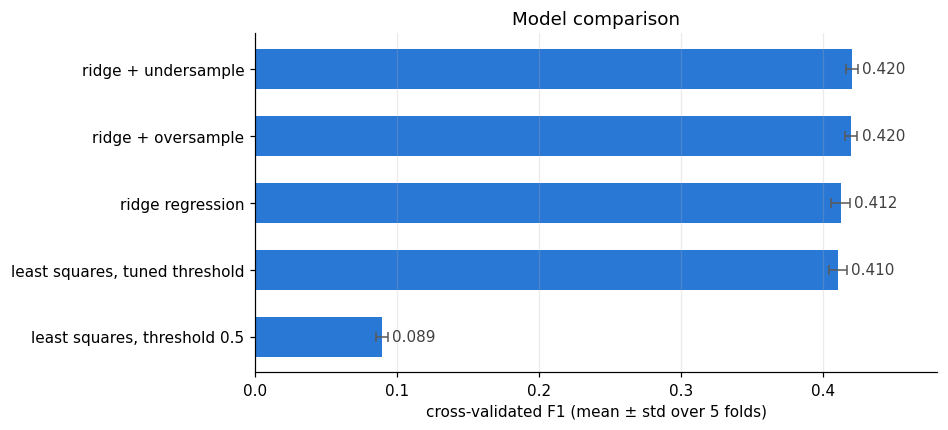

In [12]:
names = [row[0] for row in summary][::-1]
means = np.array([row[1]["f1_mean"] for row in summary])[::-1]
stds = np.array([row[1]["f1_std"] for row in summary])[::-1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(names, means, xerr=stds, color=BLUE, height=0.6,
        error_kw={"ecolor": "0.35", "elinewidth": 1, "capsize": 3})
for i, value in enumerate(means):
    ax.text(value + stds[i] + 0.003, i, f"{value:.3f}", va="center", color="0.25")
ax.set_xlim(0, means.max() + 0.06)
ax.set_xlabel("cross-validated F1 (mean ± std over 5 folds)")
ax.set_title("Model comparison")
ax.grid(axis="y", visible=False)
plt.show()

## 8. Final model and submission

We take the best row of the summary, retrain it on **all** training rows (with the same rebalancing, if any) and
predict the test set with the threshold chosen by cross-validation. The predicted positive rate on the test set
should be close to the out-of-fold one; a big gap would mean the threshold does not transfer.

In [13]:
from helpers import create_csv_submission
import implementations as impl

final_name, final_cv, final_params = summary[0]
resample_fns = {"undersample": random_undersample, "oversample": random_oversample}
resample_fn = next((fn for key, fn in resample_fns.items() if key in final_name), None)
print(f"final model: {final_name}, {format_params(final_params)}, threshold = {final_cv['threshold']:.4f}")

data = np.load(PROJECT_ROOT / "dataset/prepared/clean_full.npz", allow_pickle=True)
tx_test = np.c_[np.ones(len(data["x_test"])), data["x_test"].astype(np.float64)]
test_ids = data["test_ids"]

tx_fit, y_fit = (tx, y) if resample_fn is None else resample_fn(tx, y, seed=SEED)
if "ridge" in final_name:
    w_final, _ = impl.ridge_regression(y_fit, tx_fit, final_params["lambda_"])
else:
    w_final, _ = impl.least_squares(y_fit, tx_fit)
print(f"trained on {len(y_fit)} rows ({y_fit.mean():.1%} positive)")

test_predictions = np.where(tx_test @ w_final >= final_cv["threshold"], 1, -1)
oof_rate = np.mean(final_cv["oof_scores"] >= final_cv["threshold"]) if "oof_scores" in final_cv else np.nan
print(f"predicted positive rate: test {np.mean(test_predictions == 1):.4f}, out-of-fold {oof_rate:.4f}")

submission_path = PROJECT_ROOT / "submission_ridge.csv"
create_csv_submission(test_ids, test_predictions, submission_path)
print(f"submission written to {submission_path}")

final model: ridge + undersample, lambda_=0.001, threshold = 0.6725
trained on 57950 rows (50.0% positive)
predicted positive rate: test 0.1400, out-of-fold 0.1402
submission written to /Users/ema/Desktop/EPFL/Machine Learning/ML_Project1/submission_ridge.csv


## 9. Conclusions

CONCLUSIONS_PLACEHOLDER